# TP1 — Parte IV | EPH 2026-T1

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from os.path import join
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

AZUL = "#0F285A"
DORADO = "#AA8448"
GRIS_AZUL = "#607896"

In [2]:
# Buscar TP_01 desde el directorio actual o desde alguna de sus carpetas superiores
# (igual que en las Partes I, II y III: funciona si VS Code abre el notebook desde C_Programs o desde TP_01).
carpetas = [Path.cwd(), *Path.cwd().parents]
candidatas = carpetas + [p / "TP_01" for p in carpetas]
main_path = next(
    (p for p in candidatas if (p / "B_Outputs" / "B_Data" / "EPH_T126_limpia.csv").is_file()),
    None
)
if main_path is None:
    raise FileNotFoundError("No se encontró TP_01/B_Outputs/B_Data/EPH_T126_limpia.csv. "
                            "Abrir el repositorio en VS Code.")

# Carpetas del proyecto
a_path = join(main_path, "A_Inputs")
b_path = join(main_path, "B_Outputs")
c_path = join(main_path, "C_Programs")

# Carpetas secundarias
b_path_data = join(b_path, "B_Data")
b_path_figr = join(b_path, "B_Figure")
b_path_tabl = join(b_path, "B_Table")

## Lectura de la base limpia
Usamos la partición de la Parte I (columna `conjunto`); no se vuelve a dividir.

In [3]:
base = pd.read_csv(join(b_path_data, "EPH_T126_limpia.csv"))

train = base.loc[base["conjunto"] == "train"]
test = base.loc[base["conjunto"] == "test"]

X_train = train.drop(columns=["informal", "conjunto"])     # incluye la columna const
X_test = test.drop(columns=["informal", "conjunto"])
y_train = train["informal"].astype(int)
y_test = test["informal"].astype(int)

assert X_train.columns.equals(X_test.columns) and X_train.columns[0] == "const"
assert X_train.shape == (13692, 69) and X_test.shape == (5868, 69)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print(f"informalidad en testeo: {y_test.mean():.2%}")

X_train: (13692, 69) | X_test: (5868, 69)
informalidad en testeo: 43.52%


## Inciso 10. Estimación de los tres modelos y probabilidades en la muestra de testeo
Ahora vamos a comparar los resulados con la meustra de testeo.

In [4]:
# Regresión logística (X incluye la constante)
logit = sm.Logit(y_train, X_train).fit(disp=0)
p_logit = logit.predict(X_test)

# Análisis discriminante lineal (sin la constante)
X_train_sc = X_train.drop(columns="const")
X_test_sc = X_test.drop(columns="const")
lda = LinearDiscriminantAnalysis().fit(X_train_sc, y_train)
p_lda = lda.predict_proba(X_test_sc)[:, 1]

# Vecinos cercanos con el K de la validación cruzada (Parte III), con variables estandarizadas
cv_knn = pd.read_csv(join(b_path_tabl, "tabla_knn_cv.csv"))
k_cv = int(cv_knn.loc[cv_knn["accuracy_promedio"].idxmax(), "K"])
escala = StandardScaler().fit(X_train_sc)
knn = KNeighborsClassifier(n_neighbors=k_cv).fit(escala.transform(X_train_sc), y_train)
p_knn = knn.predict_proba(escala.transform(X_test_sc))[:, 1]

print("K elegido por validación cruzada:", k_cv)
modelos = {"Logit": p_logit, "LDA": p_lda, f"KNN (K = {k_cv})": p_knn}

K elegido por validación cruzada: 300


### Matriz de confusión (umbral 0,5)
`confusion_matrix` de sklearn ordena `vn, fp, fn, vp`: filas = lo que pasó, columnas = lo que se predijo.

In [5]:
resultados = []
for nombre, p in modelos.items():
    y_hat = (p > 0.5).astype(int)                      # clasificador de Bayes
    vn, fp, fn, vp = confusion_matrix(y_test, y_hat).ravel()
    resultados.append({"modelo": nombre, "vn": vn, "fp": fp, "fn": fn, "vp": vp})
    print(nombre)
    print(confusion_matrix(y_test, y_hat), "\n")

tabla_conf = pd.DataFrame(resultados).set_index("modelo")
tabla_conf.to_csv(join(b_path_tabl, "tabla_matriz_confusion.csv"), encoding="utf-8-sig")
tabla_conf

Logit
[[2755  559]
 [ 531 2023]] 

LDA
[[2733  581]
 [ 526 2028]] 

KNN (K = 300)
[[2518  796]
 [ 445 2109]] 



,vn,fp,fn,vp
modelo,,,,
Logit,2755,559,531,2023
LDA,2733,581,526,2028
KNN (K = 300),2518,796,445,2109


### Métricas de desempeño en la muestra de testeo
Exactitud, sensibilidad (tvp), especificidad (1 − tfp), valor predictivo positivo y área bajo la curva ROC (AROC). Se agrega como referencia un clasificador que predice siempre la clase mayoritaria.

In [6]:
filas = []
for nombre, p in modelos.items():
    vn, fp, fn, vp = tabla_conf.loc[nombre, ["vn", "fp", "fn", "vp"]]
    P, N = vp + fn, vn + fp                            # positivos y negativos verdaderos
    filas.append({
        "modelo": nombre,
        "exactitud": (vp + vn) / (P + N),
        "sensibilidad": vp / P,
        "especificidad": vn / N,
        "vpp": vp / (vp + fp),
        "aroc": roc_auc_score(y_test, p),
    })

tabla_metricas = pd.DataFrame(filas).set_index("modelo")
tabla_metricas.to_csv(join(b_path_tabl, "tabla_metricas_testeo.csv"), encoding="utf-8-sig")
display(tabla_metricas.round(3))

mayoritaria = max(y_test.mean(), 1 - y_test.mean())
print(f"exactitud de predecir siempre la clase mayoritaria: {mayoritaria:.3f}")

,exactitud,sensibilidad,especificidad,vpp,aroc
modelo,,,,,
Logit,0.814,0.792,0.831,0.784,0.892
LDA,0.811,0.794,0.825,0.777,0.888
KNN (K = 300),0.789,0.826,0.760,0.726,0.872


exactitud de predecir siempre la clase mayoritaria: 0.565


### Curva ROC de los tres modelos

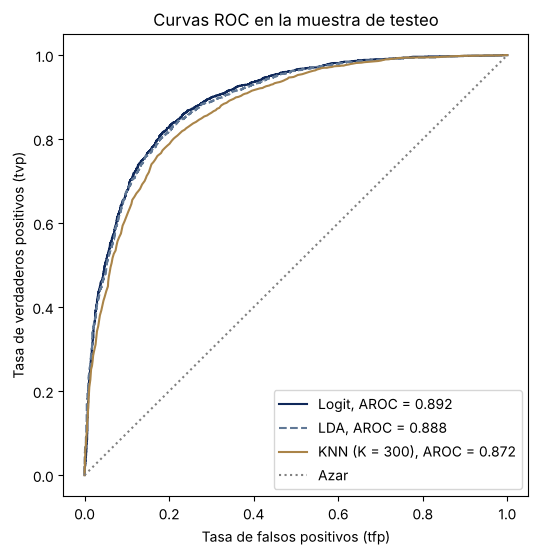

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))

estilos = [(AZUL, "-"), (GRIS_AZUL, "--"), (DORADO, "-")]
for (nombre, p), (color, linea) in zip(modelos.items(), estilos):
    tfp, tvp, _ = roc_curve(y_test, p)
    ax.plot(tfp, tvp, color=color, linestyle=linea,
            label=f"{nombre}, AROC = {roc_auc_score(y_test, p):.3f}")

ax.plot([0, 1], [0, 1], color="gray", linestyle=":", label="Azar")
ax.set_title("Curvas ROC en la muestra de testeo")
ax.set_xlabel("Tasa de falsos positivos (tfp)")
ax.set_ylabel("Tasa de verdaderos positivos (tvp)")
ax.legend(loc="lower right")
fig.savefig(join(b_path_figr, "curvas_roc_testeo.png"), dpi=200, bbox_inches="tight")
plt.show()

## Tablas LaTeX para el informe
Generamos los archivos `.tex` que se incluyen en `parte_04.tex`, a partir de los CSV de este notebook.

In [8]:
def coma(x, d=3):
    return f"{x:.{d}f}".replace(".", ",")

# Matrices de confusión (filas: lo observado; columnas: lo predicho)
bloques = []
for nombre in tabla_conf.index:
    f = tabla_conf.loc[nombre]
    bloques.append(
        rf"\multicolumn{{3}}{{l}}{{\textbf{{{nombre}}}}} \\" + "\n"
        + rf"Observado formal (0) & {int(f['vn'])} & {int(f['fp'])} \\" + "\n"
        + rf"Observado informal (1) & {int(f['fn'])} & {int(f['vp'])} \\"
    )
tex_conf = "\n".join([
    r"\begin{table}[H]",
    r"\caption{Matrices de confusión en la muestra de testeo (umbral $p>0,5$)}",
    r"\label{tab:matriz_confusion}", r"\centering", r"\footnotesize",
    r"\begin{tabular}{lrr}", r"\toprule",
    r" & Predicho formal (0) & Predicho informal (1) \\", r"\midrule",
    ("\n" + r"\midrule" + "\n").join(bloques),
    r"\bottomrule", r"\end{tabular}", r"\end{table}",
]) + "\n"
(Path(b_path_tabl) / "tabla_matriz_confusion.tex").write_text(tex_conf, encoding="utf-8")

# Métricas de desempeño
filas = [
    f"{nombre} & {coma(m['exactitud'])} & {coma(m['sensibilidad'])} & {coma(m['especificidad'])}"
    f" & {coma(m['vpp'])} & {coma(m['aroc'])} \\\\"
    for nombre, m in tabla_metricas.iterrows()
]
tex_met = "\n".join([
    r"\begin{table}[H]",
    r"\caption{Métricas de desempeño en la muestra de testeo (umbral $p>0,5$)}",
    r"\label{tab:metricas_testeo}", r"\centering", r"\footnotesize",
    r"\begin{tabular}{lrrrrr}", r"\toprule",
    r"Modelo & Exactitud & Sensibilidad & Especificidad & VPP & AROC \\",
    r"\midrule", *filas, r"\bottomrule", r"\end{tabular}", r"\end{table}",
]) + "\n"
(Path(b_path_tabl) / "tabla_metricas_testeo.tex").write_text(tex_met, encoding="utf-8")
print("Tablas LaTeX guardadas en B_Outputs/B_Table.")

Tablas LaTeX guardadas en B_Outputs/B_Table.
